# 02 — Phân chia chuỗi thời gian & Tiền xử lý (Fit trên Train, Transform sang Val/Test)

Theo đúng nguyên tắc bất biến của Học máy (Machine Learning):
1. **Phân chia chuỗi thời gian TRƯỚC khi tiền xử lý**: Dữ liệu panel sản phẩm–tuần được chia tách rành mạch thành Train (80%), Validation (10%) và Test (10%) theo mốc tuần `order_purchase_timestamp`.
2. **Fit DUY NHẤT trên Train**: Toàn bộ các bước chuẩn hóa, điền khuyết, kẹp ngoại lai và mã hóa One-Hot (`CustomDataPipeline`) chỉ được học (fit) trên tập Train (`train_df`).
3. **Transform độc lập sang Validation và Test**: Áp dụng các tham số thống kê đã đóng băng từ Train sang Validation (`val_df`) và Test (`test_df`), ngăn chặn 100% rủi ro rò rỉ dữ liệu (Data Leakage).

In [1]:
get_ipython().run_line_magic("matplotlib", "inline")
import sys
import json
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config
from src.data.loader import load_raw_sales_data
from src.data.builder import build_weekly_sales_dataset
from src.data.preprocessing import CustomDataPipeline, weekly_split_data
from src.models import regressors, persistence
from src.deployment import predictor
from src.evaluation import metrics, error_analysis

plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
def show_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(config.NOTEBOOK_FIGURES_DIR / filename, dpi=config.FIGURE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def revenue(log_values):
    return np.maximum(0.0, np.expm1(np.asarray(log_values, dtype=float)))

print("Trình thông dịch Trình thông dịch Python:", sys.executable)
print("Thư mục dự án:", PROJECT_ROOT)

Trình thông dịch Trình thông dịch Python: e:\Hoc_May_Tren_truong\lab_2 sales_predictor\.venv\Scripts\python.exe
Thư mục dự án: e:\Hoc_May_Tren_truong\lab_2 sales_predictor


## 1. Phân chia chuỗi thời gian 8:1:1 (Temporal Split) TRƯỚC khi Tiền xử lý

Áp dụng nguyên tắc chia dữ liệu trước khi tiền xử lý. Tỷ lệ 80/10/10 được phân bổ theo số tuần target, đảm bảo toàn bộ sản phẩm cùng tuần nằm trong cùng một tập và các mốc thời gian không bao giờ bị chồng lấn hay xáo trộn ngẫu nhiên.

In [2]:
raw = load_raw_sales_data()
panel = build_weekly_sales_dataset(raw)
train_df, val_df, test_df = weekly_split_data(panel)
split_summary = pd.DataFrame([
    {"Split": name, "Product-weeks": len(frame), "Weeks": frame[config.TIMESTAMP_COLUMN].nunique(),
     "Start": frame[config.TIMESTAMP_COLUMN].min(), "End": frame[config.TIMESTAMP_COLUMN].max(),
     "Zero sales (%)": frame.sales.eq(0).mean() * 100}
    for name, frame in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]
])
display(split_summary)
assert train_df[config.TIMESTAMP_COLUMN].max() < val_df[config.TIMESTAMP_COLUMN].min()
assert val_df[config.TIMESTAMP_COLUMN].max() < test_df[config.TIMESTAMP_COLUMN].min()

[2026-10-20 21:22:01] [INFO] [sales_predictor]: [DATA AUDIT] Tham số reviews=None; tự động nạp dữ liệu đánh giá từ tệp chuẩn: E:\Hoc_May_Tren_truong\lab_2 sales_predictor\data\raw\olist_order_reviews_dataset.csv


,Split,Product-weeks,Weeks,Start,End,Zero sales (%)
0,Train,655066,78,2016-10-10,2018-04-02,95.401532
1,Validation,249399,10,2018-04-09,2018-06-11,96.937438
2,Test,293717,10,2018-06-18,2018-08-20,97.392388


## 2. Ý nghĩa và thời điểm có sẵn của đặc trưng

| Nhóm | Đặc trưng | Có sẵn khi forecast |
|---|---|---|
| Doanh thu trước đó | `last_week_sales`, `sales_lag_2_weeks`, `sales_lag_4_weeks` | Tuần lịch trước target 1, 2, 4 tuần |
| Xu hướng gần | `sales_mean_4_weeks`, `sales_std_4_weeks` | Tối đa bốn tuần trước target |
| Giá/lượng đã quan sát | `price`, `last_week_units` | Giá trung bình tuần bán gần nhất trước target; lượng bán tuần trước |
| Tuổi lịch sử | `weeks_since_first_sale` | Số tuần kể từ lần bán đầu tiên được quan sát |
| Lịch | `month_sin`, `month_cos`, `is_peak_shopping_season` | Tính từ tuần target đã biết trước |
| Sản phẩm | `category` | Danh mục ghi nhận đầu tiên |

`product_id`, `sales`, tuổi/giới tính giả lập, marketing mô phỏng và review hiện tại không nằm trong X. Thiếu các nhóm dữ liệu thực của đề được ghi nhận là hạn chế, không thay bằng dữ liệu ngẫu nhiên rồi diễn giải như quan sát.

In [3]:
display(pd.DataFrame({"Numerical input": config.WEEKLY_NUMERICAL_COLS}))
display(pd.DataFrame({"Categorical input": config.WEEKLY_CATEGORICAL_COLS}))
sample_product = train_df.product_id.iloc[0]
display(train_df.loc[train_df.product_id == sample_product].head(8))

,Numerical input
0,past_review_count
1,past_review_rating
2,customer_past_spend
3,customer_past_orders
4,customer_state_count
5,price
6,last_week_sales
7,sales_lag_2_weeks
8,sales_lag_4_weeks
9,sales_mean_4_weeks


,Categorical input
0,category


,product_id,order_purchase_timestamp,category,price,sales,last_week_sales,sales_lag_2_weeks,sales_lag_4_weeks,sales_mean_4_weeks,sales_std_4_weeks,last_week_units,weeks_since_first_sale,customer_past_spend,customer_past_orders,customer_state_count,past_review_count,past_review_rating
0,027cdd14a677a5834bc67a9789db5021,2016-10-10,perfumaria,89.9,0.0,89.9,0.0,0.0,89.900000,0.000000,1.0,1,0.0,0.0,1,0.0,0.0
208,027cdd14a677a5834bc67a9789db5021,2016-10-17,perfumaria,89.9,0.0,0.0,89.9,0.0,44.950000,44.950000,0.0,2,0.0,0.0,1,0.0,0.0
447,027cdd14a677a5834bc67a9789db5021,2016-10-24,perfumaria,89.9,0.0,0.0,0.0,0.0,29.966667,42.379266,0.0,3,0.0,0.0,1,0.0,0.0
686,027cdd14a677a5834bc67a9789db5021,2016-10-31,perfumaria,89.9,0.0,0.0,0.0,89.9,22.475000,38.927842,0.0,4,0.0,0.0,1,0.0,0.0
925,027cdd14a677a5834bc67a9789db5021,2016-11-07,perfumaria,89.9,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,5,0.0,0.0,1,1.0,5.0
1164,027cdd14a677a5834bc67a9789db5021,2016-11-14,perfumaria,89.9,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,6,0.0,0.0,1,1.0,5.0
1403,027cdd14a677a5834bc67a9789db5021,2016-11-21,perfumaria,89.9,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,7,0.0,0.0,1,1.0,5.0
1642,027cdd14a677a5834bc67a9789db5021,2016-11-28,perfumaria,89.9,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,8,0.0,0.0,1,1.0,5.0


## 3. Fit Pipeline DUY NHẤT trên Train, Transform sang Validation và Test

Nguyên tắc cốt lõi:
- `pipeline.fit(train_df)`: Chỉ tính toán median điền khuyết, ngưỡng kẹp ngoại lai IQR, danh mục One-Hot và mean/std chuẩn hóa từ `train_df`.
- `pipeline.transform()`: Áp dụng độc lập sang `train_df`, `val_df`, và `test_df`.
- Nhãn mục tiêu `y` được trích xuất và biến đổi `log1p(sales)` độc lập cho từng tập.
- Ma trận đặc trưng đầu ra được lưu trữ dưới dạng ma trận thưa CSR (`data/processed`) kèm fingerprint để tái sử dụng.


★★★★★★★★★★★★ BƯỚC 5: PHÂN CHIA CHUỖI THỜI GIAN 8:1:1 & FIT PIPELINE ★★★★★★★★★★★★

[2026-10-20 21:22:04] [INFO] [sales_predictor]: Thực hiện phân chia Temporal Split 8:1:1 theo order_purchase_timestamp...
[2026-10-20 21:22:05] [INFO] [sales_predictor]:   • Tập Train (80%): 655,066 dòng
[2026-10-20 21:22:05] [INFO] [sales_predictor]:   • Tập Val   (10%): 249,399 dòng
[2026-10-20 21:22:05] [INFO] [sales_predictor]:   • Tập Test  (10%): 293,717 dòng
[2026-10-20 21:22:05] [INFO] [sales_predictor]: Đang xuất biểu đồ: [Phân bố Mẫu Phân chia Chuỗi thời gian (Temporal Split 8:1:1)]...


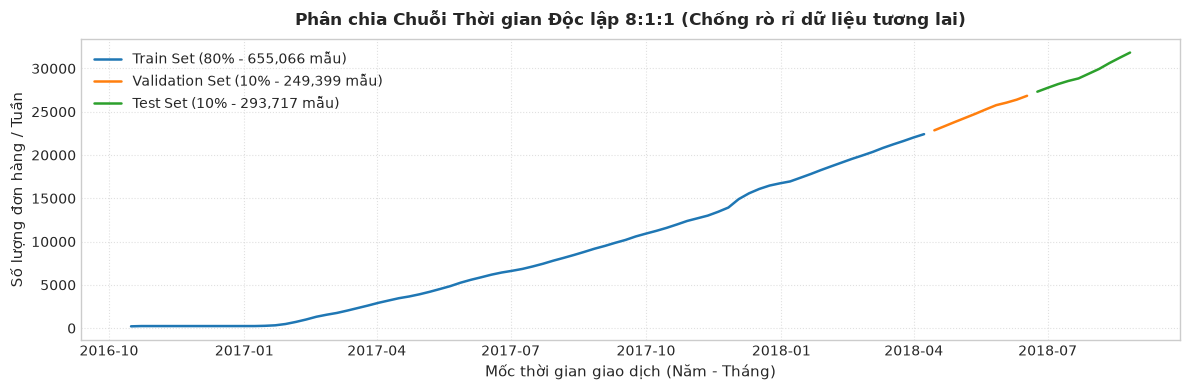

[2026-10-20 21:22:05] [INFO] [sales_predictor]: Khởi tạo và Fit CustomDataPipeline trên tập Train...
[2026-10-20 21:22:19] [INFO] [sales_predictor]: ✓ Đã lưu cache tiền xử lý & artifacts notebook vào: E:\Hoc_May_Tren_truong\lab_2 sales_predictor\data\processed


,Split,Shape,Features,Non-finite values
0,Train,"(655066, 89)",89,0
1,Validation,"(249399, 89)",89,0
2,Test,"(293717, 89)",89,0


,Encoded feature
0,past_review_count
1,past_review_rating
2,customer_past_spend
3,customer_past_orders
4,customer_state_count
...,...
84,category_sinalizacao_e_seguranca
85,category_tablets_impressao_imagem
86,category_telefonia
87,category_telefonia_fixa


In [4]:
from main import step_5_split_and_pipeline
X_train, X_val, X_test, y_train, y_val, y_test, pipeline = step_5_split_and_pipeline(
    df=panel,
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    force_reprocess=True
)
display(pd.DataFrame([
    {"Tập dữ liệu": name, "Kích thước ma trận (Shape)": str(X.shape), "Số đặc trưng": X.shape[1], "Giá trị không hợp lệ (NaN/Inf)": int((~np.isfinite(X.data)).sum())}
    for name, X in [("Train (80%)", X_train), ("Validation (10%)", X_val), ("Test (10%)", X_test)]
]))
display(pd.DataFrame({"Đặc trưng đã mã hóa": pipeline.feature_names_}))

## 4. Kiểm tra tính nhất quán và bàn giao

Đọc lại pipeline phải cho cùng ma trận và nhãn. Đối chiếu một mẫu dương với một mẫu 0 để tránh chỉ kiểm tra một loại target. Lưu khóa product/week của Test và vài bản ghi demo để notebook 04–05 truy vết dự đoán; chúng không được dùng để fit mô hình.

In [5]:
loaded = CustomDataPipeline.load(config.CACHE_PIPELINE)
positions = list(np.flatnonzero(test_df.sales.to_numpy() > 0)[:3]) + list(np.flatnonzero(test_df.sales.to_numpy() == 0)[:2])
demo_rows = test_df.iloc[positions]
X_check, y_check = loaded.transform(demo_rows)
np.testing.assert_allclose(X_check, X_test[positions].toarray())
np.testing.assert_allclose(y_check, y_test[positions])
np.testing.assert_allclose(revenue(y_train), train_df.sales.to_numpy())
assert all(np.isfinite(X.data).all() for X in [X_train, X_val, X_test])
assert train_df.sales.eq(0).any()
test_df[["product_id", config.TIMESTAMP_COLUMN]].to_csv(config.PROCESSED_DATA_DIR / "weekly_test_keys.csv.gz", index=False)
cache_fingerprint = json.loads((config.PROCESSED_DATA_DIR / "cache_manifest.json").read_text(encoding="utf-8"))["fingerprint"]
demo_payload = {"fingerprint": cache_fingerprint, "positions": [int(i) for i in positions],
                "rows": json.loads(demo_rows.to_json(orient="records", date_format="iso"))}
(config.PROCESSED_DATA_DIR / "weekly_demo_rows.json").write_text(json.dumps(demo_payload, ensure_ascii=False), encoding="utf-8")
display(Markdown(f"""### Kết quả kiểm chứng
- Pipeline có **{len(pipeline.feature_names_)}** features sau mã hóa; cấu hình gốc có **{len(config.WEEKLY_NUMERICAL_COLS)}** cột số và **{len(config.WEEKLY_CATEGORICAL_COLS)}** cột category.
- Đã xác nhận ma trận sau load, nhãn log và target 0; Train/Validation/Test có lần lượt **{len(y_train):,} / {len(y_val):,} / {len(y_test):,}** mẫu.
- Cache và bản ghi demo đã sẵn sàng cho notebook 03–05. Các kiểm tra này không thay thế kiểm toán độ trễ dữ liệu nguồn trong production.
"""))

### Kết quả kiểm chứng
- Pipeline có **89** features sau mã hóa; cấu hình gốc có **16** cột số và **1** cột category.
- Đã xác nhận ma trận sau load, nhãn log và target 0; Train/Validation/Test có lần lượt **655,066 / 249,399 / 293,717** mẫu.
- Cache và bản ghi demo đã sẵn sàng cho notebook 03–05. Các kiểm tra này không thay thế kiểm toán độ trễ dữ liệu nguồn trong production.


## 5. Ví dụ có thể đối soát: item → calendar week → lịch sử

Lấy một sản phẩm có nhiều tuần bán trong Train. Bảng item đã aggregation được so với panel, gồm cả tuần 0. Kiểm tra một target cụ thể: lag-1 bằng doanh thu tuần lịch ngay trước đó; rolling-mean bằng tối đa bốn tuần trước target; giá là mean của tuần có giao dịch gần nhất đã hoàn tất.

In [6]:
product = train_df.groupby("product_id").sales.apply(lambda s: (s > 0).sum()).idxmax()
source = raw.loc[raw.product_id == product, [config.TIMESTAMP_COLUMN, "price"]].copy()
source["week"] = pd.to_datetime(source[config.TIMESTAMP_COLUMN]).dt.to_period("W-SUN").dt.start_time
source_weekly = source.groupby("week").agg(source_sales=("price", "sum"), source_units=("price", "size"), source_price=("price", "mean"))
walkthrough = train_df.loc[train_df.product_id == product].copy()
display(walkthrough.merge(source_weekly, left_on=config.TIMESTAMP_COLUMN, right_index=True, how="left").head(12))
row = walkthrough.iloc[min(8, len(walkthrough)-1)]
target_week = row[config.TIMESTAMP_COLUMN]
calendar = pd.date_range(target_week - pd.Timedelta(weeks=4), target_week - pd.Timedelta(weeks=1), freq="W-MON")
previous_sales = source_weekly.source_sales.reindex(calendar, fill_value=0)
np.testing.assert_allclose(row.last_week_sales, previous_sales.iloc[-1])
np.testing.assert_allclose(row.sales_mean_4_weeks, previous_sales.mean())
prior_prices = source_weekly.loc[source_weekly.index < target_week, "source_price"]
np.testing.assert_allclose(row.price, prior_prices.iloc[-1])
display(pd.DataFrame({"Prior calendar week": calendar, "Revenue BRL": previous_sales.to_numpy()}))
print("Tuần target đã đối soát:", target_week, "doanh thu tuần trước:", row.last_week_sales, "trung bình trượt:", row.sales_mean_4_weeks, "giá đã quan sát trước target:", row.price)

,product_id,order_purchase_timestamp,category,price,sales,last_week_sales,sales_lag_2_weeks,sales_lag_4_weeks,sales_mean_4_weeks,sales_std_4_weeks,last_week_units,weeks_since_first_sale,customer_past_spend,customer_past_orders,customer_state_count,past_review_count,past_review_rating,source_sales,source_units,source_price
5321,7c1bd920dbdf22470b68bde975dd3ccf,2017-02-06,beleza_saude,64.99,64.99,64.99,0.00,0.00,64.9900,0.000000,1.0,1,0.000000,0.000000,1,0.0,0.000000,64.99,1.0,64.99
6486,7c1bd920dbdf22470b68bde975dd3ccf,2017-02-13,beleza_saude,64.99,64.99,64.99,64.99,0.00,64.9900,0.000000,1.0,2,0.000000,0.000000,1,1.0,5.000000,64.99,1.0,64.99
7915,7c1bd920dbdf22470b68bde975dd3ccf,2017-02-20,beleza_saude,64.99,194.97,64.99,64.99,0.00,64.9900,0.000000,1.0,3,0.000000,0.000000,1,1.0,5.000000,194.97,3.0,64.99
9574,7c1bd920dbdf22470b68bde975dd3ccf,2017-02-27,beleza_saude,64.99,64.99,194.97,64.99,64.99,97.4850,56.282991,3.0,4,0.000000,0.000000,3,2.0,3.000000,64.99,1.0,64.99
11456,7c1bd920dbdf22470b68bde975dd3ccf,2017-03-06,beleza_saude,64.99,259.96,64.99,194.97,64.99,97.4850,56.282991,1.0,5,0.000000,0.000000,1,2.0,3.000000,259.96,4.0,64.99
13618,7c1bd920dbdf22470b68bde975dd3ccf,2017-03-13,beleza_saude,64.99,194.97,259.96,64.99,64.99,146.2275,84.424486,4.0,6,0.000000,0.000000,3,2.0,3.000000,194.97,3.0,64.99
16078,7c1bd920dbdf22470b68bde975dd3ccf,2017-03-20,beleza_saude,64.99,64.99,194.97,259.96,194.97,178.7225,70.821211,3.0,7,0.000000,0.000000,3,6.0,3.000000,64.99,1.0,64.99
18846,7c1bd920dbdf22470b68bde975dd3ccf,2017-03-27,beleza_saude,64.99,0.00,64.99,194.97,64.99,146.2275,84.424486,1.0,8,0.000000,0.000000,1,12.0,3.583333,NaN,NaN,NaN
21895,7c1bd920dbdf22470b68bde975dd3ccf,2017-04-03,beleza_saude,64.99,64.99,0.00,64.99,259.96,129.9800,102.758213,0.0,9,0.000000,0.000000,1,13.0,3.384615,64.99,1.0,64.99
25206,7c1bd920dbdf22470b68bde975dd3ccf,2017-04-10,beleza_saude,64.99,64.99,64.99,0.00,194.97,81.2375,70.821211,1.0,10,0.000000,0.000000,1,14.0,3.428571,64.99,1.0,64.99


,Prior calendar week,Revenue BRL
0,2017-03-06,259.96
1,2017-03-13,194.97
2,2017-03-20,64.99
3,2017-03-27,0.00


Tuần target đã đối soát: 2017-04-03 00:00:00 doanh thu tuần trước: 0.0 trung bình trượt: 129.98 giá đã quan sát trước target: 64.99


## 6. Kiểm tra tính nhân quả của feature bằng dữ liệu kiểm soát

Tạo một chuỗi nhỏ có một tuần không bán. Thay giá trị giao dịch hiện tại và tương lai, giữ nguyên khoảng coverage. Input của các target trước hoặc tại cutoff phải giữ nguyên; nhãn target tại cutoff được phép đổi. Kiểm tra này tập trung vào builder, không khẳng định đã kiểm toán mọi độ trễ dữ liệu nguồn.

In [7]:
weeks = pd.date_range("2020-01-06", periods=12, freq="W-MON")
toy = pd.DataFrame([{"product_id": "demo", "order_id": str(i), "order_item_id": 9, "price": float(10+i), "category": "demo", config.TIMESTAMP_COLUMN: week + pd.Timedelta(days=1)} for i, week in enumerate(weeks) if i != 4])
before = build_weekly_sales_dataset(toy)
cutoff = weeks[7]
changed = toy.copy()
changed.loc[changed[config.TIMESTAMP_COLUMN] >= cutoff, "price"] *= 100
after = build_weekly_sales_dataset(changed)
input_cols = [c for c in before.columns if c != "sales"]
pd.testing.assert_frame_equal(before.loc[before[config.TIMESTAMP_COLUMN] <= cutoff, input_cols], after.loc[after[config.TIMESTAMP_COLUMN] <= cutoff, input_cols])
zero_week = before.loc[before[config.TIMESTAMP_COLUMN] == weeks[4]].iloc[0]
assert zero_week.sales == 0 and zero_week.last_week_sales == 13
display(before)
print("ĐẠT: giữ tuần không bán; số thứ tự 9 không phải số lượng; thay dữ liệu hiện tại/tương lai không đổi đầu vào quá khứ.")

[2026-10-20 21:22:25] [INFO] [sales_predictor]: [DATA AUDIT] Tham số reviews=None; tự động nạp dữ liệu đánh giá từ tệp chuẩn: E:\Hoc_May_Tren_truong\lab_2 sales_predictor\data\raw\olist_order_reviews_dataset.csv
[2026-10-20 21:22:25] [INFO] [sales_predictor]: [DATA AUDIT] Tham số reviews=None; tự động nạp dữ liệu đánh giá từ tệp chuẩn: E:\Hoc_May_Tren_truong\lab_2 sales_predictor\data\raw\olist_order_reviews_dataset.csv


,product_id,order_purchase_timestamp,category,price,sales,last_week_sales,sales_lag_2_weeks,sales_lag_4_weeks,sales_mean_4_weeks,sales_std_4_weeks,last_week_units,weeks_since_first_sale,customer_past_spend,customer_past_orders,customer_state_count,past_review_count,past_review_rating
0,demo,2020-01-20,demo,11.0,12.0,11.0,0.0,0.0,11.0,0.000000,1.0,1,0.0,0.0,0.0,0.0,0.0
1,demo,2020-01-27,demo,12.0,13.0,12.0,11.0,0.0,11.5,0.500000,1.0,2,0.0,0.0,0.0,0.0,0.0
2,demo,2020-02-03,demo,13.0,0.0,13.0,12.0,0.0,12.0,0.816497,1.0,3,0.0,0.0,0.0,0.0,0.0
3,demo,2020-02-10,demo,13.0,15.0,0.0,13.0,11.0,9.0,5.244044,0.0,4,0.0,0.0,0.0,0.0,0.0
4,demo,2020-02-17,demo,15.0,16.0,15.0,0.0,12.0,10.0,5.873670,1.0,5,0.0,0.0,0.0,0.0,0.0
5,demo,2020-02-24,demo,16.0,17.0,16.0,15.0,13.0,11.0,6.442049,1.0,6,0.0,0.0,0.0,0.0,0.0
6,demo,2020-03-02,demo,17.0,18.0,17.0,16.0,0.0,12.0,6.964194,1.0,7,0.0,0.0,0.0,0.0,0.0
7,demo,2020-03-09,demo,18.0,19.0,18.0,17.0,15.0,16.5,1.118034,1.0,8,0.0,0.0,0.0,0.0,0.0
8,demo,2020-03-16,demo,19.0,20.0,19.0,18.0,16.0,17.5,1.118034,1.0,9,0.0,0.0,0.0,0.0,0.0


ĐẠT: giữ tuần không bán; số thứ tự 9 không phải số lượng; thay dữ liệu hiện tại/tương lai không đổi đầu vào quá khứ.


## 7. Thống kê trước/sau scaler và category mới

Scaler lưu mean/std Train; Validation không bị ép có mean 0 hoặc std 1. Không fit lại scaler trên Validation. Category không thấy khi fit được mã hóa toàn 0; điều này hỗ trợ xử lý đầu vào nhưng không bảo đảm chất lượng forecast cho danh mục mới.

,Feature,Raw Train mean,Saved mean,Scaled Train mean,Scaled Train std,Scaled Validation mean
0,past_review_count,2.311909,2.311909,0.000000e+00,1.0,0.101461
1,past_review_rating,3.827343,3.827343,-3.609844e-16,1.0,0.053159
2,customer_past_spend,2.963550,2.963550,-1.804922e-17,1.0,0.030941
3,customer_past_orders,0.023889,0.023889,5.692447e-17,1.0,0.050171
4,customer_state_count,1.058785,1.058785,-1.516829e-16,1.0,-0.028534
5,price,141.996836,141.996836,-1.096837e-16,1.0,0.002390
6,last_week_sales,13.336412,13.336412,-1.388402e-17,1.0,-0.045398
7,sales_lag_2_weeks,13.033023,13.033023,-3.887525e-17,1.0,-0.042977
8,sales_lag_4_weeks,12.369685,12.369685,1.943762e-17,1.0,-0.032042
9,sales_mean_4_weeks,18.990882,18.990882,3.054484e-17,1.0,-0.065679


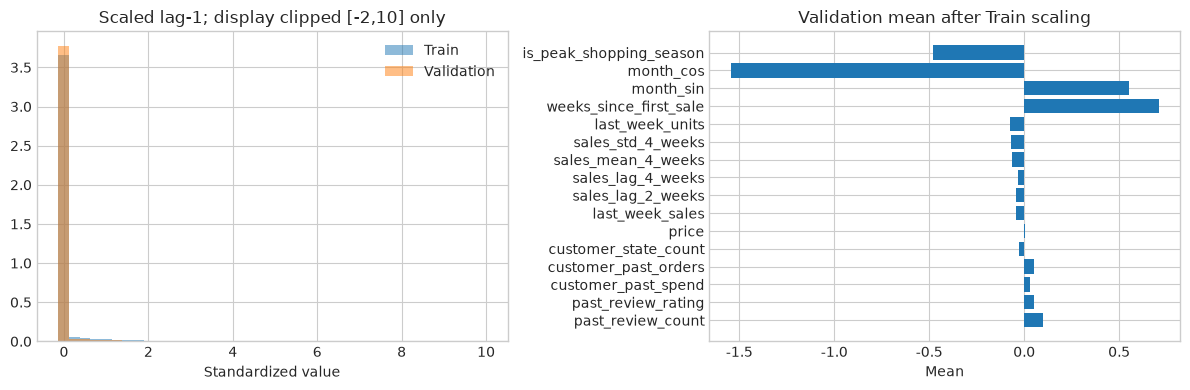

Đã xác nhận category mới thành vector one-hot 0 và transform không sửa mean scaler. Histogram chỉ cắt trục để dễ đọc; pipeline vẫn giữ nguyên các giá trị cực trị.

In [8]:
engineered_train = pipeline.feature_engineer.transform(train_df)
engineered_val = pipeline.feature_engineer.transform(val_df)
scaled_train = pipeline.scaler.transform(pipeline.imputer.transform(engineered_train)[pipeline.num_cols].to_numpy())
scaled_val = pipeline.scaler.transform(pipeline.imputer.transform(engineered_val)[pipeline.num_cols].to_numpy())
scaler_audit = pd.DataFrame({"Feature": pipeline.num_cols, "Raw Train mean": engineered_train[pipeline.num_cols].mean().to_numpy(), "Saved mean": pipeline.scaler.mean_, "Scaled Train mean": scaled_train.mean(axis=0), "Scaled Train std": scaled_train.std(axis=0), "Scaled Validation mean": scaled_val.mean(axis=0)})
display(scaler_audit)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, values in [("Train", scaled_train[:, pipeline.num_cols.index("last_week_sales")]), ("Validation", scaled_val[:, pipeline.num_cols.index("last_week_sales")])]:
    axes[0].hist(np.clip(values, -2, 10), bins=40, alpha=.5, density=True, label=label)
axes[0].legend(); axes[0].set(title="Scaled lag-1; display clipped [-2,10] only", xlabel="Standardized value")
axes[1].barh(scaler_audit.Feature, scaler_audit["Scaled Validation mean"])
axes[1].set(title="Validation mean after Train scaling", xlabel="Mean")
show_figure(fig, "weekly_02_scaler_audit.png")
unseen = train_df.iloc[[0]].copy(); unseen["category"] = "__unseen_category__"
encoded = pipeline.encoder.transform(pipeline.feature_engineer.transform(unseen))
assert np.count_nonzero(encoded) == 0
stats_before = pipeline.scaler.mean_.copy()
pipeline.transform(unseen)
np.testing.assert_array_equal(pipeline.scaler.mean_, stats_before)
display(Markdown("Đã xác nhận category mới thành vector one-hot 0 và transform không sửa mean scaler. Histogram chỉ cắt trục để dễ đọc; pipeline vẫn giữ nguyên các giá trị cực trị."))

## 8. Kiểm tra cache và các bất biến bàn giao

Gọi lại cùng dữ liệu phải nạp được cache và cho cùng ma trận/nhãn. Đổi một target trong bản sao dùng để tính fingerprint phải làm fingerprint đổi; không ghi bản sao đó vào cache. Các bất biến gồm tuần thứ Hai, khóa product/week duy nhất, target không âm và X không chứa target.

In [9]:
from main import preprocessing_fingerprint
cached = step_5_split_and_pipeline(panel, force_reprocess=False)
np.testing.assert_array_equal(cached[3], y_train)
assert (cached[0] != X_train).nnz == 0
modified = panel.copy(); modified.loc[0, "sales"] += 1
assert preprocessing_fingerprint(modified) != preprocessing_fingerprint(panel)
assert not panel.duplicated(["product_id", config.TIMESTAMP_COLUMN]).any()
assert panel[config.TIMESTAMP_COLUMN].dt.dayofweek.eq(0).all()
assert panel.sales.ge(0).all()
assert "sales" not in pipeline.num_cols and "product_id" not in pipeline.cat_cols
print("ĐẠT: đọc lại cache, vô hiệu hóa fingerprint, khóa sản phẩm–tuần, target thứ Hai, doanh thu không âm và không dùng target làm đầu vào.")


★★★★★★★★★★★★ BƯỚC 5: PHÂN CHIA CHUỖI THỜI GIAN 8:1:1 & FIT PIPELINE ★★★★★★★★★★★★

[2026-10-20 21:22:30] [INFO] [sales_predictor]: 📁 Đã tìm thấy ma trận đặc trưng hợp lệ trong cache data/processed. Tải trực tiếp...
[2026-10-20 21:22:31] [INFO] [sales_predictor]: ✓ Nạp xong ma trận trong 0.79s: X_train=(655066, 89), X_val=(249399, 89), X_test=(293717, 89)
ĐẠT: đọc lại cache, vô hiệu hóa fingerprint, khóa sản phẩm–tuần, target thứ Hai, doanh thu không âm và không dùng target làm đầu vào.
